In [ ]:
# 11. Implement a Feedforward Neural Network to classify different clothing 
# items. Use Dense layers and display predicted class labels for five test 
# images. Use -- Fashion-MNIST dataset. 

In [1]:
# Import required libraries

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
# Load Fashion-MNIST dataset directly from Keras

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Display dataset shapes

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 45s 2us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 8s 2us/step
Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)


In [3]:
# Normalize pixel values between 0 and 1

X_train = X_train / 255.0
X_test = X_test / 255.0

# Flatten images from 28x28 into 784 values

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (60000, 784)
Testing Shape: (10000, 784)


In [4]:
# Create Feedforward Neural Network

model = tf.keras.Sequential([

    # Input layer
    tf.keras.layers.Input(shape=(784,)),

    # First hidden layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Second hidden layer
    tf.keras.layers.Dense(64, activation='relu'),

    # Output layer for 10 clothing classes
    tf.keras.layers.Dense(10, activation='softmax')
])

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Compile the FNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [6]:
# Train the model

model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8105 - loss: 0.5491
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8622 - loss: 0.3871
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8738 - loss: 0.3479
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8816 - loss: 0.3226
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8876 - loss: 0.3037
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8941 - loss: 0.2885
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9000 - loss: 0.2737
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9036 - loss: 0.2623
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9070 - loss: 0.2523
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9104 - loss: 0.2429


In [7]:
# Predict test images

predictions = model.predict(X_test)

# Get predicted class numbers

predicted_labels = np.argmax(predictions, axis=1)

print("Predictions completed!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions completed!


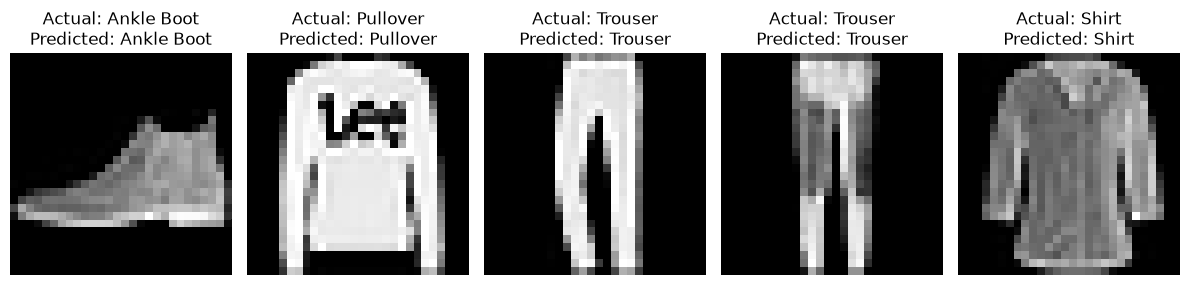

In [8]:
# Define clothing class names

class_names = [
    'T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle Boot'
]

# Display five test images

plt.figure(figsize=(12, 5))

for i in range(5):

    # Get actual and predicted labels
    actual = class_names[y_test[i]]
    predicted = class_names[predicted_labels[i]]

    # Display image
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    # Display actual and predicted labels
    plt.title("Actual: " + actual + "\nPredicted: " + predicted)
    plt.axis('off')

plt.tight_layout()
plt.show()